## B8 · Working with dates and times

Converting text to dates, parts of a date, date arithmetic, dates as an index, resampling, and plotting time series.

In [641]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

# Sample orders with dates stored as text in three different styles
df_orders = pd.DataFrame({
    "us_date":    ["12/21/2023 14:30", "01/13/2023 09:15", "03/15/2023 18:45", "03/05/2023 12:00"],
    "mixed_date": ["01/02/2023 14:30", "13/01/2023 09:15", "2023-03-15 18:45", "March 5, 2023 12:00"],
    "uk_date":    ["21/12/2023 14:30", "13/01/2023 09:15", "15/03/2023 18:45", "05/03/2023 12:00"],
    "delivery_days": [3, 5, 2, 10],
    "sales": [150, 200, 300, 400],
})

# A made-up daily weather record for two years, used in many examples
rng = np.random.default_rng(0)
dates = pd.date_range("2023-01-01", "2024-12-31", freq="D")
doy = dates.dayofyear
df_weather = pd.DataFrame({
    "date": dates,
    "temp_c": (10 + 8 * np.sin(2 * np.pi * (doy - 110) / 365) + rng.normal(0, 2, len(dates))).round(1),
    "rain_mm": rng.gamma(0.7, 4, len(dates)).round(1),
})

### Creating dates

#### Converting text to dates

**B8.01**

`pd.to_datetime(s)`

***(non-examinable)***

The `pd.to_datetime()` function allows us to turn text such as `12/21/2023 14:30` into real datetime values. It is useful because dates loaded from files are usually only text, which cannot be sorted by date, subtracted or plotted properly. Alternatively, use `parse_dates=` in `read_csv` to convert while loading.

Dates read from a file are usually only text (dtype `object`). `pd.to_datetime` turns them into real dates that can be sorted, subtracted and plotted. By default pandas assumes **US order: month/day/year**.

In [642]:
df_orders.dtypes                 # us_date is 'object': only text

us_date          object
mixed_date       object
uk_date          object
delivery_days     int64
sales             int64
dtype: object

In [643]:
df_orders["clean_date"] = pd.to_datetime(df_orders["us_date"])
df_orders['clean_date']

0   2023-12-21 14:30:00
1   2023-01-13 09:15:00
2   2023-03-15 18:45:00
3   2023-03-05 12:00:00
Name: clean_date, dtype: datetime64[ns]

*See also:* Reading dates when loading a CSV (B8) · Checking a column is a datetime (B8) · Reading day-first dates (B8) · Handling invalid dates as `NaT` (B8)

#### Reading day-first dates

**B8.02**

`pd.to_datetime(s, dayfirst=True)`

***(non-examinable)***

The `dayfirst=True` option allows us to read dates written day/month/year. It is useful because pandas assumes US month-first order, so `01/02/2023` would silently become 2 January. Alternatively, give an explicit `format=` such as `%d/%m/%Y`.

`01/02/2023` is 2 January in the US but 1 February in the UK. With `dayfirst=True` pandas reads day/month/year. Getting this wrong silently swaps days and months.

In [644]:
col_us = pd.to_datetime(pd.Series(["01/02/2023"]))                    # month first
col_uk = pd.to_datetime(pd.Series(["01/02/2023"]), dayfirst=True)     # day first
print(f"default : {col_us[0].date()}")

default : 2023-01-02


In [645]:
print(f"dayfirst: {col_uk[0].date()}")

dayfirst: 2023-02-01


In [646]:
pd.to_datetime(df_orders["uk_date"], dayfirst=True)

0   2023-12-21 14:30:00
1   2023-01-13 09:15:00
2   2023-03-15 18:45:00
3   2023-03-05 12:00:00
Name: uk_date, dtype: datetime64[ns]

*See also:* Converting text to dates (B8) · Reading mixed date styles (B8)

#### Reading mixed date styles

**B8.03**

`pd.to_datetime(s, dayfirst=True, format="mixed")`

***(non-examinable)***

The `format="mixed"` option allows us to parse a column where each value is written in a different style. It is useful for inconsistent data from several sources. Alternatively, clean the strings into one style first, or parse each style separately.

If the styles differ between rows, `format="mixed"` makes pandas work out each value separately.

In [647]:
# display the example data
df_orders["mixed_date"]

0       01/02/2023 14:30
1       13/01/2023 09:15
2       2023-03-15 18:45
3    March 5, 2023 12:00
Name: mixed_date, dtype: object

In [648]:
pd.to_datetime(df_orders["mixed_date"], dayfirst=True, format="mixed")

0   2023-02-01 14:30:00
1   2023-01-13 09:15:00
2   2023-03-15 18:45:00
3   2023-03-05 12:00:00
Name: mixed_date, dtype: datetime64[ns]

*See also:* Reading day-first dates (B8) · Giving an explicit date format (B8) · Handling invalid dates as `NaT` (B8)

#### Giving an explicit date format

**B8.04**

`pd.to_datetime(s, format="%d/%m/%Y")`

***(non-examinable)***

The `format=` argument allows us to state exactly how the dates are laid out, using codes like `%d/%m/%Y`. It is useful because it is unambiguous and fast. Alternatively, `dayfirst=True` lets pandas guess the rest.

The most reliable (and fastest) way is to state the pattern explicitly using format codes: `%d` day, `%m` month, `%Y` 4-digit year, `%H:%M` hours and minutes.

In [649]:
# display the example data
s = pd.Series(["03/04/2024", "15/04/2024", "01/05/2024"])
s

0    03/04/2024
1    15/04/2024
2    01/05/2024
dtype: object

In [650]:
pd.to_datetime(s, format='%d/%m/%Y')

0   2024-04-03
1   2024-04-15
2   2024-05-01
dtype: datetime64[ns]

In [651]:
col_t = pd.Series(["03/04/2024 14:30", "15/04/2024 09:05"])

In [652]:
# display example series
col_t

0    03/04/2024 14:30
1    15/04/2024 09:05
dtype: object

In [653]:
pd.to_datetime(col_t, format="%d/%m/%Y %H:%M")

0   2024-04-03 14:30:00
1   2024-04-15 09:05:00
dtype: datetime64[ns]

*See also:* Reading day-first dates (B8) · Formatting codes for dates and times (B8) · Converting text to dates (B8)

#### Handling invalid dates as `NaT`

**B8.05**

`pd.to_datetime(s, errors="coerce")`

***(non-examinable)***

The `errors="coerce"` option allows us to turn unparseable values into `NaT` (missing) instead of stopping with an error. It is useful for finding or removing the bad entries in a column. Alternatively, leave the default and fix the data when the error message points to it.

Bad values raise an error by default. `errors="coerce"` turns them into `NaT` ("not a time"), pandas' missing value for dates.

In [654]:
# display the example data
s = pd.Series(["2024-01-05", "not a date", "2024-02-30"])
s

0    2024-01-05
1    not a date
2    2024-02-30
dtype: object

In [655]:
col_d = pd.to_datetime(s, errors="coerce")
col_d

0   2024-01-05
1          NaT
2          NaT
dtype: datetime64[ns]

In [656]:
print(f"missing: {col_d.isna().sum()}")

missing: 2


*See also:* Converting text to dates (B8) · Counting missing values (B5) · Creating a range of dates (B8) · Checking a column is a datetime (B8)

#### Creating a range of dates

**B8.06**

`pd.date_range(start, periods=n, freq=code)`

***(non-examinable)***

The `pd.date_range()` function allows us to generate a regular series of dates. It is useful for building a time axis or an empty calendar. Alternatively, `np.arange` works on plain numbers but not on dates.

Make a regular sequence of dates. `freq` can be `"D"` (day), `"W"` (week), `"MS"` (month start), `"h"` (hour)…

In [657]:
pd.date_range('2024-01-01', periods=5, freq='D')

DatetimeIndex(['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04',
               '2024-01-05'],
              dtype='datetime64[ns]', freq='D')

In [658]:
pd.date_range('2024-01-01', '2024-06-01', freq='MS')   # first of each month

DatetimeIndex(['2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01',
               '2024-05-01', '2024-06-01'],
              dtype='datetime64[ns]', freq='MS')

*See also:* Creating a sequence with `np.arange` (A4) · Resampling to another frequency (B8) · Creating an array (A4) · Creating a single date or time (B8)

#### Creating a single date or time

**B8.07**

`pd.Timestamp("YYYY-MM-DD")`

***(non-examinable)***

A `pd.Timestamp` allows us to represent one specific moment. It is useful for comparing with a date column or marking a date on a plot. Alternatively, Python's `datetime.datetime` is very similar and pandas converts it automatically.

A `Timestamp` is one date and time, and is the type used for comparison with a date column.

In [659]:
t = pd.Timestamp("2024-03-01 14:30")
t

Timestamp('2024-03-01 14:30:00')

In [660]:
print(t.year, t.month, t.day, t.hour)

2024 3 1 14


In [661]:
pd.Timestamp.now().year >= 2024

True

*See also:* Converting text to dates (B8) · Filtering rows by date (B8) · Reading dates when loading a CSV (B8)

#### Reading dates when loading a CSV

**B8.08**

`pd.read_csv(f, parse_dates=['date'], index_col='date')`

***(non-examinable)***

The `parse_dates=` argument allows us to convert date columns as the file is read. It is useful when a file has date columns, because it avoids a separate `to_datetime` step. Alternatively, load the file normally and convert afterwards.

`parse_dates` converts columns to datetime as the file is read, so the separate `to_datetime` step is not needed. Here a small file is written first, to read back.

In [662]:
pd.DataFrame({"date": ["2024-01-01", "2024-01-02"], "sales": [10, 14]}).to_csv("sales_demo.csv", index=False)

In [663]:
df = pd.read_csv("sales_demo.csv", parse_dates=["date"], index_col="date")
df.index.dtype

dtype('<M8[ns]')

In [664]:
# display example data
df

,sales
date,
2024-01-01,10
2024-01-02,14


*See also:* Reading a CSV file (B1) · Setting a column as the index (B2)

### Inspecting and extracting parts

#### Checking a column is a datetime

**B8.09**

`df.dtypes, df['date'].dtype`

***(non-examinable)***

The `.dtypes` attribute allows us to confirm a column is `datetime64` rather than text. It is useful before any `.dt` operation, which fails on text. Alternatively, `df.info()` shows the types of all columns at once.

Look for `datetime64[ns]`. If it says `object`, the dates are still text.

In [665]:
df_weather.dtypes

date       datetime64[ns]
temp_c            float64
rain_mm           float64
dtype: object

In [666]:
# display example data
df_weather.head(3)

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2


*See also:* Summarising a DataFrame with `info()` (B1) · Converting text to dates (B8) · Checking the column types (B1)

#### Extracting year, month and day

**B8.10**

`s.dt.year, s.dt.month, s.dt.day`

***(non-examinable)***

The `.dt` accessor allows us to extract the year, month and day of every date as numbers. It is useful for grouping, filtering by season, or making new columns. Alternatively, with a datetime index use `df.index.year` and so on.

The `.dt` accessor gives the parts of every date in a column. Use it to make new columns.

In [667]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


In [668]:
df_w = df_weather.copy()
df_w["year"] = df_w["date"].dt.year
df_w["month"] = df_w["date"].dt.month
df_w["day"] = df_w["date"].dt.day
df_w.head()

,date,temp_c,rain_mm,year,month,day
0,2023-01-01,2.6,0.5,2023,1,1
1,2023-01-02,2.1,4.2,2023,1,2
2,2023-01-03,3.6,0.2,2023,1,3
3,2023-01-04,2.5,1.5,2023,1,4
4,2023-01-05,1.2,3.9,2023,1,5


*See also:* Getting weekday and month names (B8) · Adding a calculated column (B4) · Checking a column is a datetime (B8)

#### Getting weekday and month names

**B8.11**

`s.dt.day_name(), s.dt.month_name(), s.dt.dayofweek`

***(non-examinable)***

The `.dt.day_name()` and `.dt.month_name()` methods allow us to get the weekday or month as words. They are useful for labels in tables and charts. Alternatively, `.dt.dayofweek` gives a number (Monday = 0) that sorts correctly.

`dayofweek` counts Monday = 0 … Sunday = 6. `day_name()` and `month_name()` give text.

In [669]:
# display the example data
df_weather["date"].head(3)

0   2023-01-01
1   2023-01-02
2   2023-01-03
Name: date, dtype: datetime64[ns]

In [670]:
col_d = df_weather["date"].head(7)
pd.DataFrame({'date': col_d, 'weekday': col_d.dt.day_name(), 'number': col_d.dt.dayofweek})

,date,weekday,number
0,2023-01-01,Sunday,6
1,2023-01-02,Monday,0
2,2023-01-03,Tuesday,1
3,2023-01-04,Wednesday,2
4,2023-01-05,Thursday,3
5,2023-01-06,Friday,4
6,2023-01-07,Saturday,5


In [671]:
df_weather['date'].dt.month_name().head(2).tolist()

['January', 'January']

*See also:* Extracting year, month and day (B8) · Counting each category (B5) · Extracting hours, minutes and day of year (B8)

#### Extracting hours, minutes and day of year

**B8.12**

`s.dt.hour, s.dt.minute, s.dt.dayofyear`

***(non-examinable)***

The `.dt.hour`, `.dt.minute` and `.dt.dayofyear` attributes allow us to extract finer parts of a timestamp. They are useful for questions like "is the hour after midday?" or comparing years day by day. Alternatively, `strftime` can produce them as text.

In [672]:
# display the example data
col_t = pd.Series(pd.to_datetime(["2024-03-01 14:30", "2024-07-04 09:05"]))
col_t

0   2024-03-01 14:30:00
1   2024-07-04 09:05:00
dtype: datetime64[ns]

In [673]:
print(col_t.dt.hour.tolist(), col_t.dt.minute.tolist(), col_t.dt.dayofyear.tolist())

[14, 9] [30, 5] [61, 186]


*See also:* Extracting year, month and day (B8) · Getting weekday and month names (B8)

#### Formatting dates as text

**B8.13**

`s.dt.strftime("%d %b %Y")`

***(non-examinable)***

The `.dt.strftime()` method allows us to convert dates into text laid out the way we want. It is useful for report tables and chart labels. Alternatively, matplotlib's `DateFormatter` formats the axis directly.

`strftime` is the reverse of `format=`: it shows dates in the chosen layout, as text.

In [674]:
# display the example data
df_weather["date"].head(3)

0   2023-01-01
1   2023-01-02
2   2023-01-03
Name: date, dtype: datetime64[ns]

In [675]:
col_d = df_weather["date"].head(3)
col_d.dt.strftime('%d %b %Y').tolist()     # 01 Jan 2023

['01 Jan 2023', '02 Jan 2023', '03 Jan 2023']

In [676]:
col_d.dt.strftime('%A %d %B').tolist()     # Sunday 01 January

['Sunday 01 January', 'Monday 02 January', 'Tuesday 03 January']

*See also:* Formatting the date axis (B8) · Giving an explicit date format (B8) · Converting a column to string type (B7)

#### Formatting codes for dates and times

**B8.14**

`%d %a %A | %m %b %B | %y %Y | %H %M %S`

***(non-examinable)***

Format codes such as `%d`, `%b` and `%Y` allow us to describe a date layout. They are useful because the same codes are used both to read dates (`format=`) and to write them (`strftime`). Alternatively, look them up in the Python `datetime` documentation.

The same codes are used to read dates (`format=`) and to write them (`strftime`).

| Component | Code | Example output |
|---|---|---|
| Day | `%d` `%a` `%A` | 01, 02…31 · Mon, Tue · Monday, Tuesday |
| Month | `%m` `%b` `%B` | 01…12 · Jan, Feb · January, February |
| Year | `%y` `%Y` | 23 (short) · 2023 (full) |
| Time | `%H` `%M` `%S` | 14 (24-hour clock) · 30 (minutes) · 05 (seconds) |

In [677]:
t = pd.Timestamp("2023-02-01 14:30:05")
for code in ["%d", "%a", "%A", "%m", "%b", "%B", "%y", "%Y", "%H", "%M", "%S"]:
    print(f"{code}  ->  {t.strftime(code)}")

%d  ->  01
%a  ->  Wed
%A  ->  Wednesday
%m  ->  02
%b  ->  Feb
%B  ->  February
%y  ->  23
%Y  ->  2023
%H  ->  14
%M  ->  30
%S  ->  05


*See also:* Giving an explicit date format (B8) · Formatting dates as text (B8) · Converting text to dates (B8)

### Date arithmetic

#### Subtracting dates

**B8.15**

`d2 - d1, (d2 - d1).dt.days`

***(non-examinable)***

Subtracting two dates allows us to calculate how much time lies between them, as a `Timedelta`. It is useful for durations between two dates. Alternatively, `.diff()` gives the gap between consecutive rows.

Subtracting dates gives a `Timedelta`. Use `.dt.days` (or `.dt.total_seconds()`) for a plain number.

In [678]:
# display the example data
df_trips = pd.DataFrame({
    "start": pd.to_datetime(["2024-03-01", "2024-03-10", "2024-04-02"]),
    "end":   pd.to_datetime(["2024-03-05", "2024-03-12", "2024-04-30"]),
})
df_trips

,start,end
0,2024-03-01,2024-03-05
1,2024-03-10,2024-03-12
2,2024-04-02,2024-04-30


In [679]:
df_trips["length"] = df_trips["end"] - df_trips["start"]
df_trips["days"] = df_trips["length"].dt.days
df_trips

,start,end,length,days
0,2024-03-01,2024-03-05,4 days,4
1,2024-03-10,2024-03-12,2 days,2
2,2024-04-02,2024-04-30,28 days,28


In [680]:
print(f'a single difference: {pd.Timestamp("2024-12-25") - pd.Timestamp("2024-03-01")}')

a single difference: 299 days 00:00:00


*See also:* Calculating changes between rows (B8) · Adding or subtracting time (B8) · Converting text to dates (B8)

#### Adding or subtracting time

**B8.16**

`d + pd.Timedelta(days=7), d + pd.DateOffset(months=1)`

***(non-examinable)***

`pd.Timedelta` and `pd.DateOffset` allow us to move a date forwards or backwards. They are useful for deadlines and follow-up dates. Alternatively, `pd.date_range` generates a whole series of dates.

`Timedelta` is an exact length of time; `DateOffset` moves by calendar units such as months (which have different lengths).

In [681]:
d = pd.Timestamp("2024-01-31")
d + pd.Timedelta(days=7)

Timestamp('2024-02-07 00:00:00')

In [682]:
d + pd.Timedelta(hours=36)

Timestamp('2024-02-01 12:00:00')

In [683]:
d + pd.DateOffset(months=1)    # 29 Feb 2024: clipped to the end of the month

Timestamp('2024-02-29 00:00:00')

In [684]:
# whole column at once
s = pd.Series(pd.to_datetime(["2024-03-01", "2024-03-15"]))

In [685]:
# display example series
s

0   2024-03-01
1   2024-03-15
dtype: datetime64[ns]

In [686]:
s + pd.Timedelta(days=30)

0   2024-03-31
1   2024-04-14
dtype: datetime64[ns]

*See also:* Creating a range of dates (B8) · Subtracting dates (B8) · Adding days from a column (B8)

#### Adding days from a column

**B8.17**

`df['date'] + pd.to_timedelta(df['delivery_days'], unit='D')`

***(non-examinable)***

The `pd.to_timedelta()` function allows us to turn a column of numbers into durations that can be added to dates. It is useful when each row has its own number of days. Alternatively, use `pd.Timedelta(days=5)` when the same duration applies to every row.

`pd.Timedelta(days=5)` is one fixed duration. When the number of days differs per row and is stored in a column, the column is converted with `pd.to_timedelta` first.

In [687]:
df_o = df_orders.copy()
df_o["clean_date"] = pd.to_datetime(df_o["uk_date"], dayfirst=True)
df_o[["clean_date", "delivery_days"]]          # before: a date and a number of days

,clean_date,delivery_days
0,2023-12-21 14:30:00,3
1,2023-01-13 09:15:00,5
2,2023-03-15 18:45:00,2
3,2023-03-05 12:00:00,10


In [688]:
df_o["est_delivery"] = df_o["clean_date"] + pd.to_timedelta(df_o["delivery_days"], unit="D")
df_o[["clean_date", "delivery_days", "est_delivery"]]    # after: the delivery date is added

,clean_date,delivery_days,est_delivery
0,2023-12-21 14:30:00,3,2023-12-24 14:30:00
1,2023-01-13 09:15:00,5,2023-01-18 09:15:00
2,2023-03-15 18:45:00,2,2023-03-17 18:45:00
3,2023-03-05 12:00:00,10,2023-03-15 12:00:00


*See also:* Adding or subtracting time (B8) · Subtracting dates (B8) · Turning timedeltas into numbers (B8) · Adding a calculated column (B4)

#### Turning timedeltas into numbers

**B8.18**

`(d2 - d1).dt.days, .dt.total_seconds()`

***(non-examinable)***

The `.dt.days` and `.dt.total_seconds()` attributes allow us to convert a duration into an ordinary number. They are useful because calculations and plots cannot use "3 days" directly. Alternatively, divide by `pd.Timedelta(days=1)` to get fractional days.

A column of "3 days" cannot be plotted or used in calculations directly. A number of days or seconds is extracted instead.

In [689]:
df_o = df_orders.copy()
df_o["clean_date"] = pd.to_datetime(df_o["uk_date"], dayfirst=True)
df_o["est_delivery"] = df_o["clean_date"] + pd.to_timedelta(df_o["delivery_days"], unit="D")
df_o["time_to_deliver"] = df_o["est_delivery"] - df_o["clean_date"]
df_o["time_to_deliver"]                  # before: timedeltas, shown as "3 days"

0    3 days
1    5 days
2    2 days
3   10 days
Name: time_to_deliver, dtype: timedelta64[ns]

In [690]:
df_o["days_int"] = df_o["time_to_deliver"].dt.days
df_o["total_seconds"] = df_o["time_to_deliver"].dt.total_seconds()
df_o[["time_to_deliver", "days_int", "total_seconds"]]    # after: plain numbers

,time_to_deliver,days_int,total_seconds
0,3 days,3,259200.0
1,5 days,5,432000.0
2,2 days,2,172800.0
3,10 days,10,864000.0


*See also:* Adding or subtracting time (B8) · Subtracting dates (B8) · Adding days from a column (B8) · Calculating changes between rows (B8)

#### Filtering rows by date

**B8.19**

`df[df['date'] >= 'YYYY-MM-DD']`

***(non-examinable)***

Comparison operators allow us to filter rows by date, using Timestamps or `YYYY-MM-DD` text. It is useful for choosing a period of interest. Alternatively, `.between()` or slicing on a datetime index does the same.

Dates can be compared with `>`, `<`, `==`, and with text in `YYYY-MM-DD` form. Combine two conditions with `&`.

In [691]:
df_march = df_weather[(df_weather["date"] >= "2024-03-01") & (df_weather["date"] < "2024-04-01")]
print(f"{len(df_march)} days in March 2024")

31 days in March 2024


In [692]:
# display example data
df_march.head(3)

,date,temp_c,rain_mm
425,2024-03-01,3.3,3.3
426,2024-03-02,1.8,1.6
427,2024-03-03,3.9,1.8


In [693]:
# warm days in summer 2024
df_summer = df_weather[df_weather["date"].between("2024-06-01", "2024-08-31")]
df_summer['temp_c'].mean().round(1)

np.float64(17.1)

*See also:* Filtering with `~`, `isin()` and `between()` (B3) · Filtering rows with a mask (B3) · Combining conditions with `&` and `|` (B3) · Sorting by date (B8)

#### Sorting by date

**B8.20**

`df.sort_values('date')`

***(non-examinable)***

The `sort_values()` method allows us to put rows in chronological order. It is useful before plotting or slicing a time series. Alternatively, `sort_index()` sorts when the date is the index.

Real dates sort chronologically. Text dates in other formats (like `03/04/2024`) would sort alphabetically, which is wrong.

In [694]:
# display the example data
df = pd.DataFrame({"date": pd.to_datetime(["2024-03-05", "2024-01-20", "2024-02-11"]), "v": [3, 1, 2]})
df

,date,v
0,2024-03-05,3
1,2024-01-20,1
2,2024-02-11,2


In [695]:
df.sort_values("date")

,date,v
1,2024-01-20,1
2,2024-02-11,2
0,2024-03-05,3


*See also:* Sorting by a column (B3) · Sorting by the index (B2) · Rounding dates to a period (B8)

#### Rounding dates to a period

**B8.21**

`s.dt.to_period("M"), s.dt.floor("D")`

***(non-examinable)***

The `.dt.to_period()` and `.dt.floor()` methods allow us to reduce a timestamp to its month or day. They are useful for grouping data by period. Alternatively, `resample` works on a datetime index.

In [696]:
# display the example data
col_t = pd.Series(pd.to_datetime(["2024-03-17 14:30", "2024-03-29 08:15"]))
col_t

0   2024-03-17 14:30:00
1   2024-03-29 08:15:00
dtype: datetime64[ns]

In [697]:
col_t.dt.to_period('M').tolist()    # month

[Period('2024-03', 'M'), Period('2024-03', 'M')]

In [698]:
col_t.dt.floor('D').tolist()        # midnight on the same day

[Timestamp('2024-03-17 00:00:00'), Timestamp('2024-03-29 00:00:00')]

*See also:* Resampling to another frequency (B8) · Grouping by month (B8) · Extracting year, month and day (B8)

### Time series data

#### Using dates as the index

**B8.22**

`df.set_index('date')`

***(non-examinable)***

The `set_index()` method allows us to make the date column the row labels. It is useful because a datetime index enables date slicing, `resample` and `rolling`. Alternatively, `index_col` and `parse_dates` do it while loading.

A `DatetimeIndex` unlocks date-based selection, `resample` and `rolling`. Most time-series work starts here.

In [699]:
df_ts = df_weather.set_index("date")
type(df_ts.index).__name__

'DatetimeIndex'

In [700]:
# display example data
df_ts.head()

,temp_c,rain_mm
date,,
2023-01-01,2.6,0.5
2023-01-02,2.1,4.2
2023-01-03,3.6,0.2
2023-01-04,2.5,1.5
2023-01-05,1.2,3.9


*See also:* Reading a CSV with a column as the index (B1) · Reading dates when loading a CSV (B8) · Setting a column as the index (B2) · Selecting rows by date text (B8)

#### Selecting rows by date text

**B8.23**

`df.loc['YYYY-MM'], df.loc['YYYY-MM':'YYYY-MM']`

***(non-examinable)***

Partial date text inside `.loc[]` allows us to select a whole year, a month or a date range. It is useful for quick time slices. Alternatively, a comparison mask on a date column does the same.

With a datetime index, partial date text works: a year, a month, or a slice between two dates (the end is **included**). Sort the index first (`sort_index()`) so slicing works as expected.

In [701]:
df_o = df_orders.copy()
df_o["clean_date"] = pd.to_datetime(df_o["uk_date"], dayfirst=True)
df_o = df_o[["clean_date", "delivery_days", "sales"]].set_index("clean_date").sort_index()
df_o

,delivery_days,sales
clean_date,,
2023-01-13 09:15:00,5,200
2023-03-05 12:00:00,10,400
2023-03-15 18:45:00,2,300
2023-12-21 14:30:00,3,150


In [702]:
print("March only:")

March only:


In [703]:
df_o.loc['2023-03']

,delivery_days,sales
clean_date,,
2023-03-05 12:00:00,10,400
2023-03-15 18:45:00,2,300


In [704]:
print("1 Jan to 31 Mar 2023 (inclusive):")

1 Jan to 31 Mar 2023 (inclusive):


In [705]:
df_o.loc['2023-01-01':'2023-03-31']

,delivery_days,sales
clean_date,,
2023-01-13 09:15:00,5,200
2023-03-05 12:00:00,10,400
2023-03-15 18:45:00,2,300


Same idea with a longer series:

In [706]:
df_ts = df_weather.set_index("date")
print(f'{len(df_ts.loc["2024"])} days in 2024')

366 days in 2024


In [707]:
print(f'{len(df_ts.loc["2024-03"])} days in March 2024')

31 days in March 2024


In [708]:
df_ts.loc["2024-02-27":"2024-03-02"]

,temp_c,rain_mm
date,,
2024-02-27,5.9,2.4
2024-02-28,3.2,0.0
2024-02-29,8.2,0.6
2024-03-01,3.3,3.3
2024-03-02,1.8,1.6


*See also:* Selecting a range of rows by label (B3) · Using dates as the index (B8) · Sorting by the index (B2) · Filtering rows by date (B8)

#### Resampling to another frequency

**B8.24**

`df.resample('W').mean()`

***(non-examinable)***

The `.resample()` method allows us to summarise data into weekly, monthly or yearly values. It is useful for smoothing noisy daily data. Alternatively, `groupby` on the month or year gives a similar result.

`resample` groups data into time periods then summarises each one: `"W"` weekly, `"ME"` month end, `"YE"` year end. Use `.mean()`, `.sum()`, `.max()`…

In [709]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


In [710]:
df_ts = df_weather.set_index("date")
df_monthly = df_ts.resample("ME").agg({"temp_c": "mean", "rain_mm": "sum"}).round(1)
df_monthly.head(6)

,temp_c,rain_mm
date,,
2023-01-31,1.8,85.6
2023-02-28,3.6,80.8
2023-03-31,5.8,72.7
2023-04-30,9.4,84.7
2023-05-31,13.4,80.6
2023-06-30,16.3,75.1


*See also:* Grouping and summarising with `groupby` (B9) · Using dates as the index (B8) · Plotting daily and monthly values together (B8) · Calculating changes between rows (B8)

#### Calculating changes between rows

**B8.25**

`s.diff(), s.pct_change(), s.shift(1)`

***(non-examinable)***

The `.diff()`, `.pct_change()` and `.shift()` methods allow us to compare each value with the previous one. They are useful for growth and day-to-day change. Alternatively, `s - s.shift(1)` gives the same result and shows what `diff()` does.

In [711]:
# display the example data
col_sales = pd.Series([100, 110, 99, 120], index=pd.date_range("2024-01-31", periods=4, freq="ME"))
col_sales

2024-01-31    100
2024-02-29    110
2024-03-31     99
2024-04-30    120
Freq: ME, dtype: int64

In [712]:
pd.DataFrame({'sales': col_sales, 'change': col_sales.diff(), 'pct': col_sales.pct_change().round(3), 'prev': col_sales.shift(1)})

,sales,change,pct,prev
2024-01-31,100,NaN,NaN,NaN
2024-02-29,110,10.0,0.100,100.0
2024-03-31,99,-11.0,-0.100,110.0
2024-04-30,120,21.0,0.212,99.0


*See also:* Resampling to another frequency (B8) · Adding days from a column (B8) · Calculating a rolling average (B8)

#### Calculating a rolling average

**B8.26**

`s.rolling(7).mean()`

***(non-examinable)***

The `.rolling(n).mean()` method allows us to average each value with its neighbours. It is useful for smoothing out day-to-day noise to show a trend. Alternatively, `resample` summarises by calendar period instead.

A rolling mean averages each value with the ones before it, smoothing out day-to-day noise. The first `window − 1` values are `NaN`.

In [713]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


In [714]:
df_ts = df_weather.set_index("date")
col_smooth = df_ts["temp_c"].rolling(7).mean()
pd.DataFrame({'raw': df_ts['temp_c'], '7-day mean': col_smooth.round(1)}).head(9)

,raw,7-day mean
date,,
2023-01-01,2.6,NaN
2023-01-02,2.1,NaN
2023-01-03,3.6,NaN
2023-01-04,2.5,NaN
2023-01-05,1.2,NaN
2023-01-06,2.9,NaN
2023-01-07,4.8,2.8
2023-01-08,4.0,3.0
2023-01-09,0.7,2.8


*See also:* Plotting a rolling average (B8) · Resampling to another frequency (B8) · Calculating changes between rows (B8)

#### Grouping by month

**B8.27**

`df.groupby(df['date'].dt.month)['temp_c'].mean()`

***(non-examinable)***

Grouping by `.dt.month` allows us to summarise data for each month of the year. It is useful for seasonal patterns. Alternatively, `resample('ME')` groups by each calendar month of each year separately.

In [715]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


In [716]:
col_by_month = df_weather.groupby(df_weather["date"].dt.month)["temp_c"].mean().round(1)
col_by_month

date
1      1.8
2      3.4
3      6.0
4      9.2
5     13.5
6     16.5
7     17.9
8     16.5
9     14.5
10    10.0
11     6.4
12     3.5
Name: temp_c, dtype: float64

*See also:* Resampling to another frequency (B8) · Extracting year, month and day (B8) · Grouping and summarising with `groupby` (B9)

### Plotting time series

#### Plotting a time series

**B8.28**

`plt.plot(df['date'], df['temp_c'])`

***(non-examinable)***

Passing a date column to `plt.plot` allows us to draw how a measurement changes over time. It is useful for any data collected through time. Alternatively, `df.plot()` or `sns.lineplot` do the same.

Put the dates on the x axis. Matplotlib understands datetime columns and picks sensible tick labels.

In [717]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


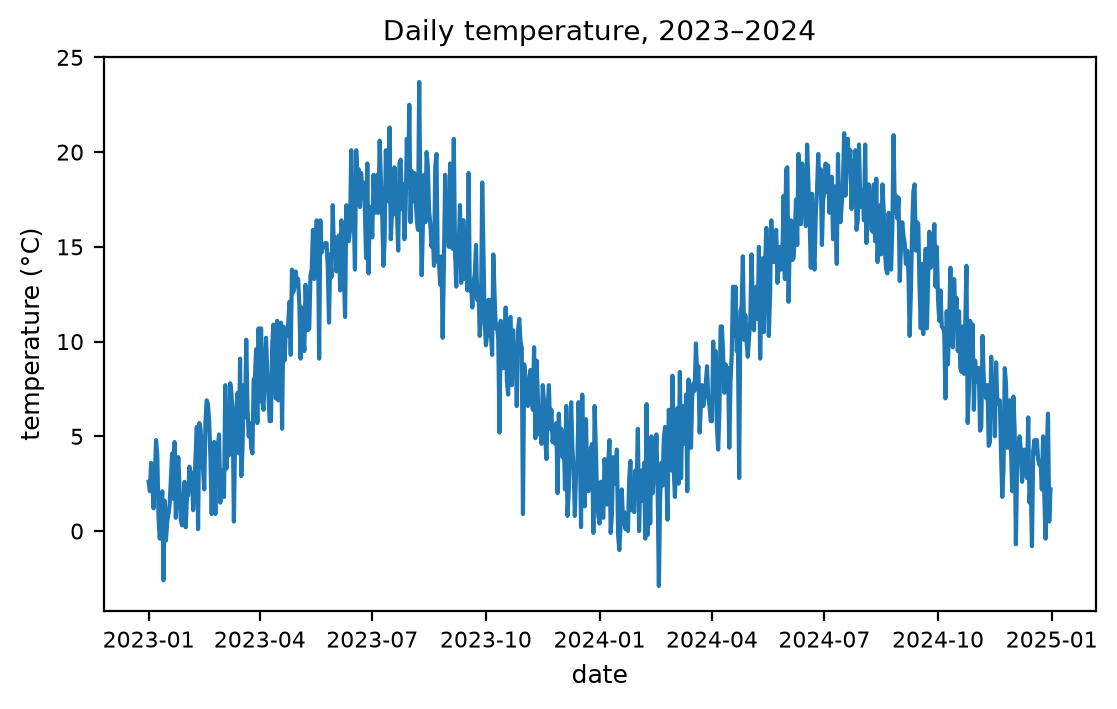

In [718]:
plt.plot(df_weather["date"], df_weather["temp_c"])
plt.xlabel("date")
plt.ylabel("temperature (°C)")
plt.title("Daily temperature, 2023–2024");

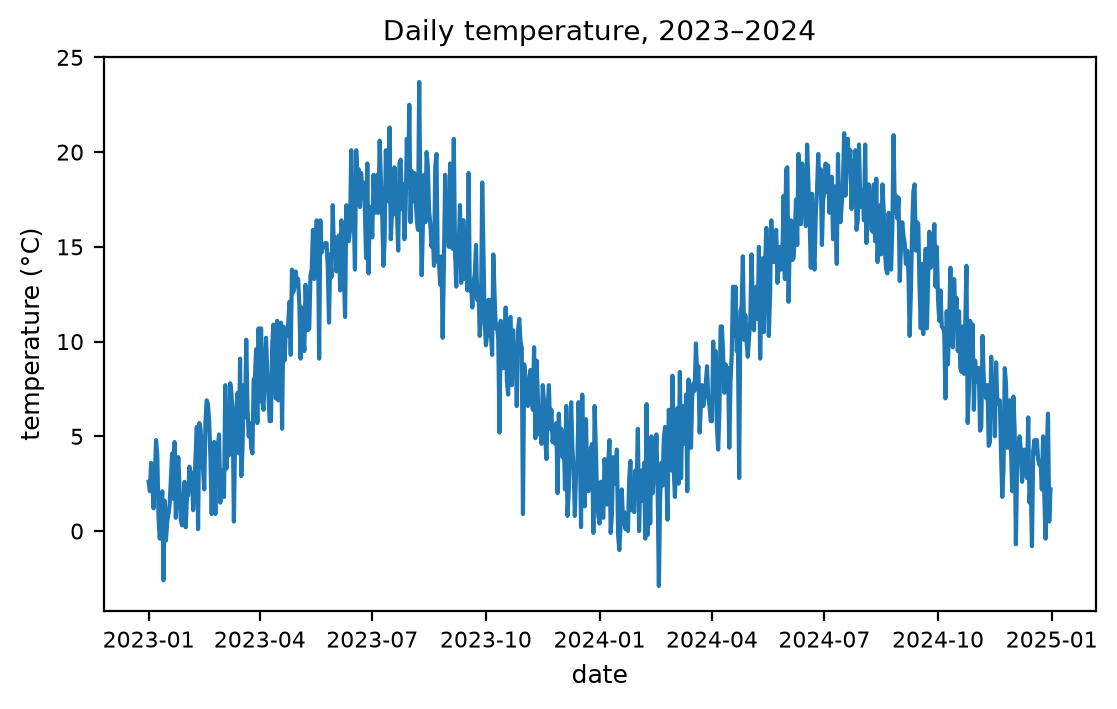

In [719]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(df_weather["date"], df_weather["temp_c"])
ax.set_xlabel("date")
ax.set_ylabel("temperature (°C)")
ax.set_title("Daily temperature, 2023–2024");

*See also:* Drawing a line plot (C3) · Drawing a simple line plot (C1) · Rotating the date labels (B8)

#### Rotating the date labels

**B8.29**

`plt.xticks(rotation=angle), fig.autofmt_xdate()`

***(non-examinable)***

The `plt.xticks(rotation=…)` function or `fig.autofmt_xdate()` allows us to stop long date labels overlapping. It is useful whenever dates fill the axis. Alternatively, a shorter date format with `DateFormatter` makes labels narrower.

Long date labels overlap. Rotate them, or let `autofmt_xdate` do it.

In [720]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


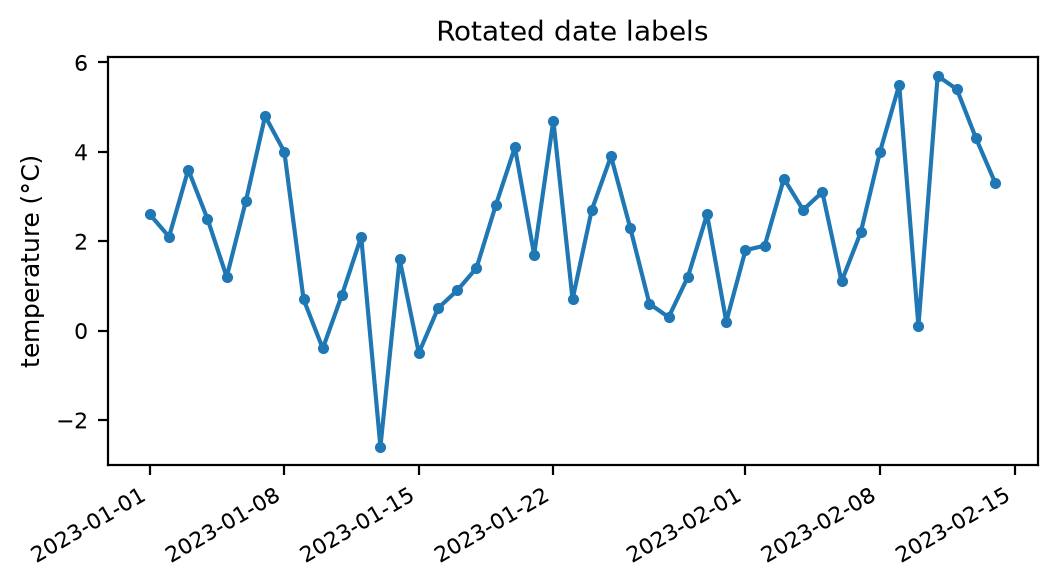

In [721]:
fig, ax = plt.subplots(figsize=(6, 3))
df_sub = df_weather[df_weather["date"] < "2023-02-15"]
ax.plot(df_sub["date"], df_sub["temp_c"], "o-", markersize=3)
fig.autofmt_xdate()          # rotates and aligns the labels
ax.set(ylabel="temperature (°C)", title="Rotated date labels");

*See also:* Plotting a time series (B8) · Setting tick positions (C1) · Formatting the date axis (B8)

#### Formatting the date axis

**B8.30**

`ax.xaxis.set_major_locator(mdates.MonthLocator()), DateFormatter`

***(non-examinable)***

Locators and formatters from `matplotlib.dates` allow us to choose where ticks appear and how they read. They are useful for tidy monthly or quarterly axes. Alternatively, accept the automatic ticks for a quick look.

`matplotlib.dates` allows the position of ticks (every month, every Monday…) and their format to be chosen (the same codes as `strftime`).

In [722]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


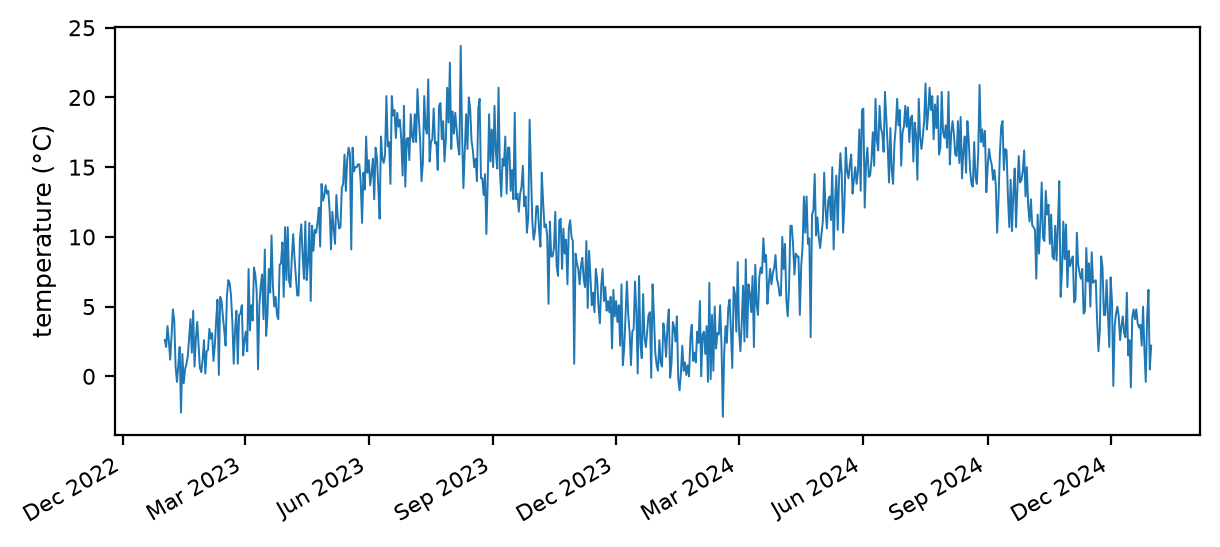

In [723]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(df_weather["date"], df_weather["temp_c"], lw=0.7)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))      # a tick every 3 months
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))      # e.g. Jan 2023
ax.set(ylabel="temperature (°C)")
fig.autofmt_xdate();

*See also:* Plotting a time series (B8) · Formatting dates as text (B8) · Rotating the date labels (B8)

#### Plotting a time series with seaborn

**B8.31**

`sns.lineplot(data=df, x='date', y='temp_c')`

***(non-examinable)***

The `sns.lineplot()` function allows us to draw a time series from a DataFrame in one line. It is useful for matching the style of other seaborn plots. Alternatively, `plt.plot` or `df.plot()` give the same picture.

In [724]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


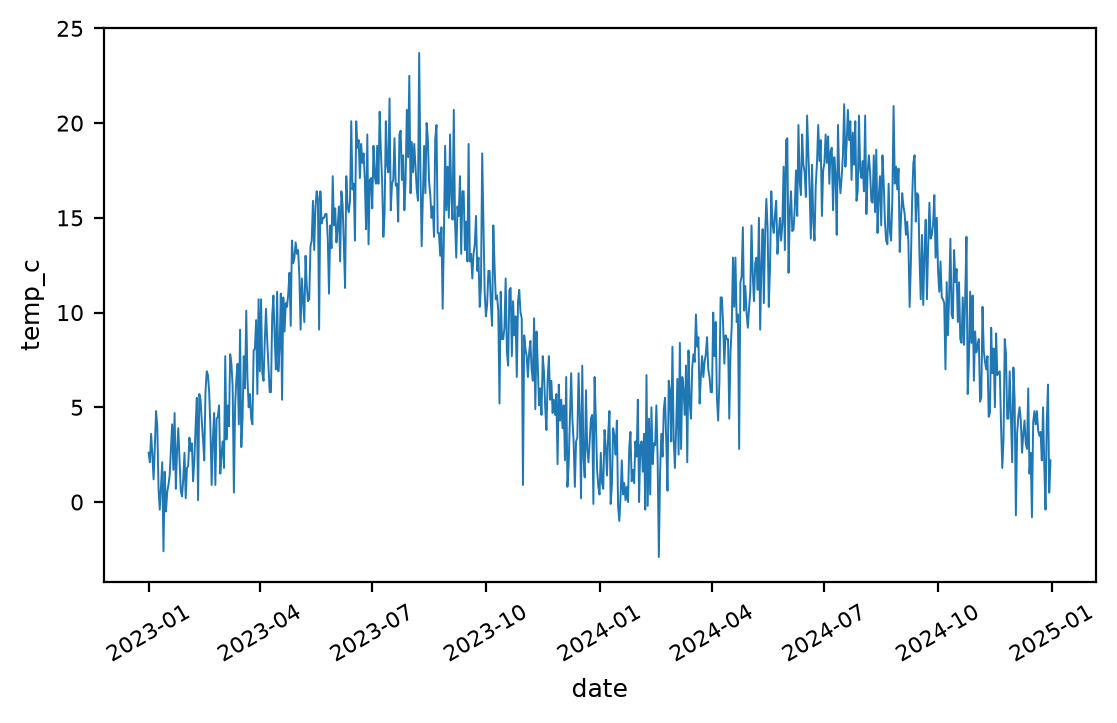

In [725]:
sns.lineplot(data=df_weather, x="date", y="temp_c", linewidth=0.7)
plt.xticks(rotation=30);

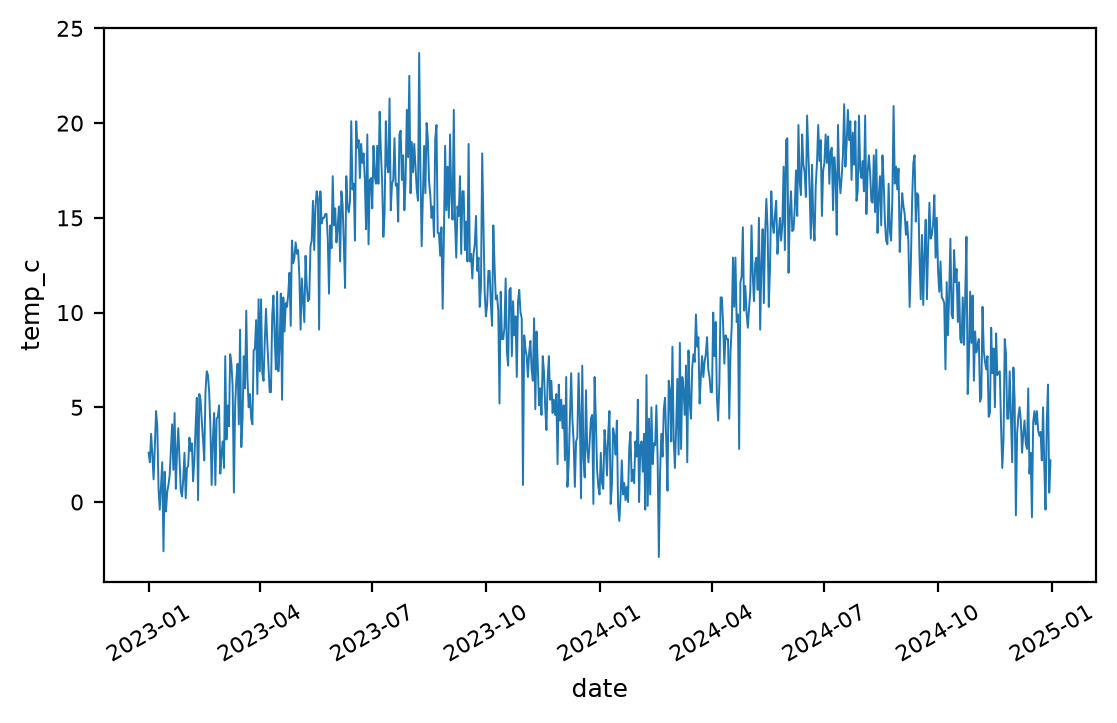

In [726]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
sns.lineplot(data=df_weather, x="date", y="temp_c", linewidth=0.7, ax=ax)
ax.tick_params(axis="x", rotation=30);

*See also:* Drawing a line plot (C3)

#### Plotting daily and monthly values together

**B8.32**

`df['col'].resample('ME').mean()`

***(non-examinable)***

If we have a long noisy series, then resampling it and plotting the summary over the raw values shows the trend without hiding the detail. It is useful for readable time series plots. Alternatively, plot only the summary if the raw data are too dense.

Resampling makes a long noisy series clearer to read. Plot both so the reader can see what was averaged.

In [727]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


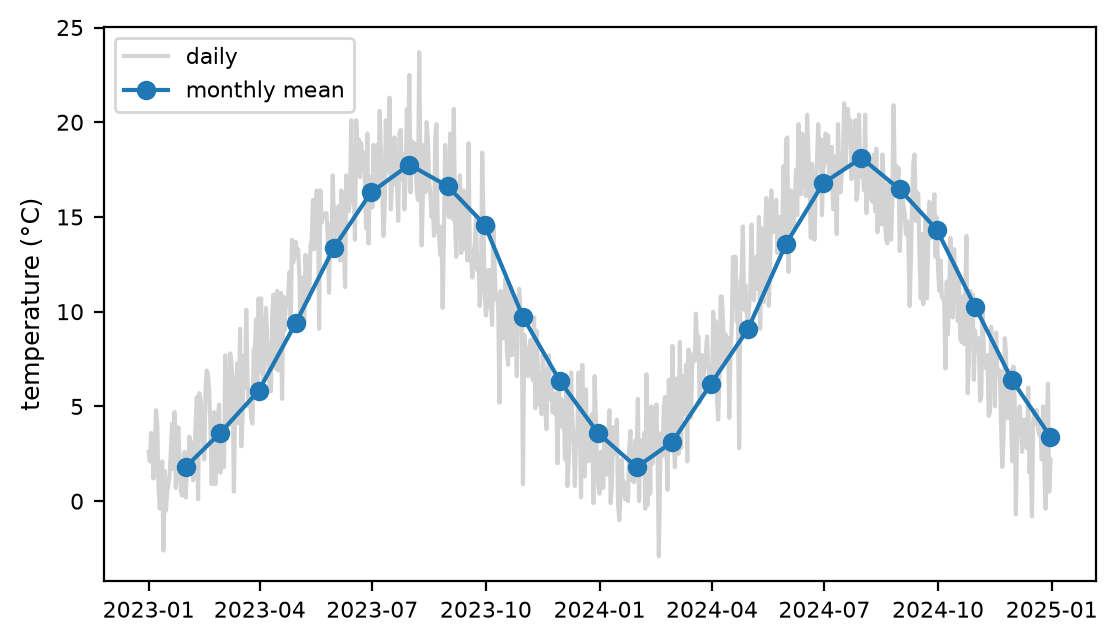

In [728]:
df_ts = df_weather.set_index("date")
col_monthly = df_ts["temp_c"].resample("ME").mean()

plt.plot(df_ts.index, df_ts["temp_c"], color="lightgrey", label="daily")
plt.plot(col_monthly.index, col_monthly, "o-", label="monthly mean")
plt.ylabel("temperature (°C)")
plt.legend();

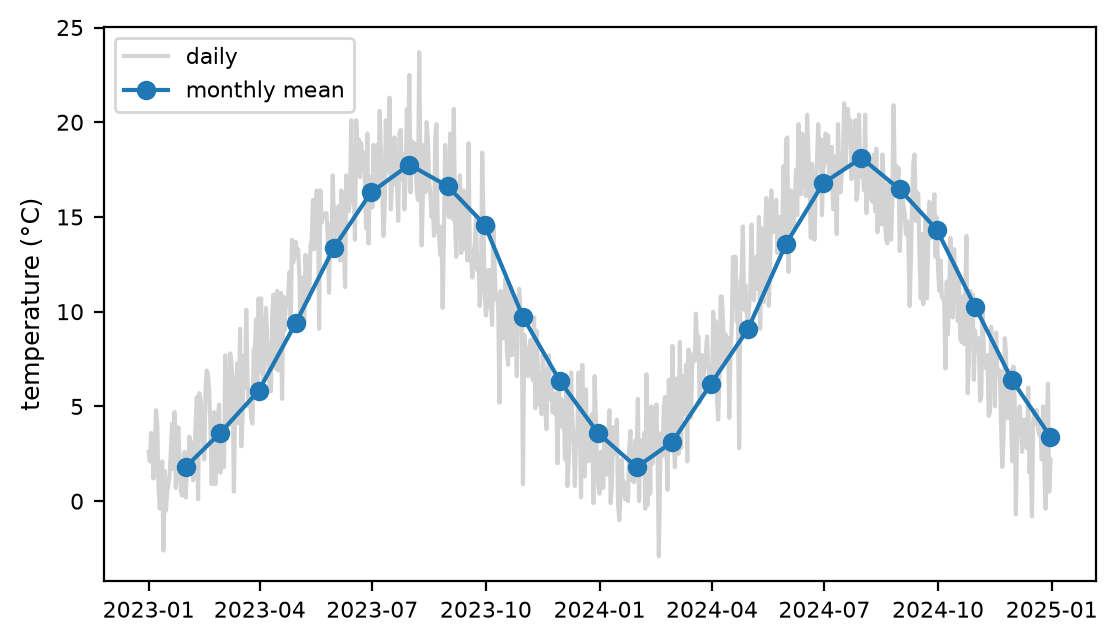

In [729]:
# the same plot in object-oriented style (ax. methods)
df_ts = df_weather.set_index("date")
col_monthly = df_ts["temp_c"].resample("ME").mean()

fig, ax = plt.subplots()
ax.plot(df_ts.index, df_ts["temp_c"], color="lightgrey", label="daily")
ax.plot(col_monthly.index, col_monthly, "o-", label="monthly mean")
ax.set_ylabel("temperature (°C)")
ax.legend();

*See also:* Resampling to another frequency (B8) · Adding a legend for several lines (C1) · Plotting a time series (B8)

#### Plotting a rolling average

**B8.33**

`plt.plot(df.index, df['col'].rolling(n).mean())`

***(non-examinable)***

Plotting `.rolling().mean()` over the raw values allows us to show a smoothed trend line. It is useful for noisy series. Alternatively, `resample` gives non-overlapping period averages.

In [730]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


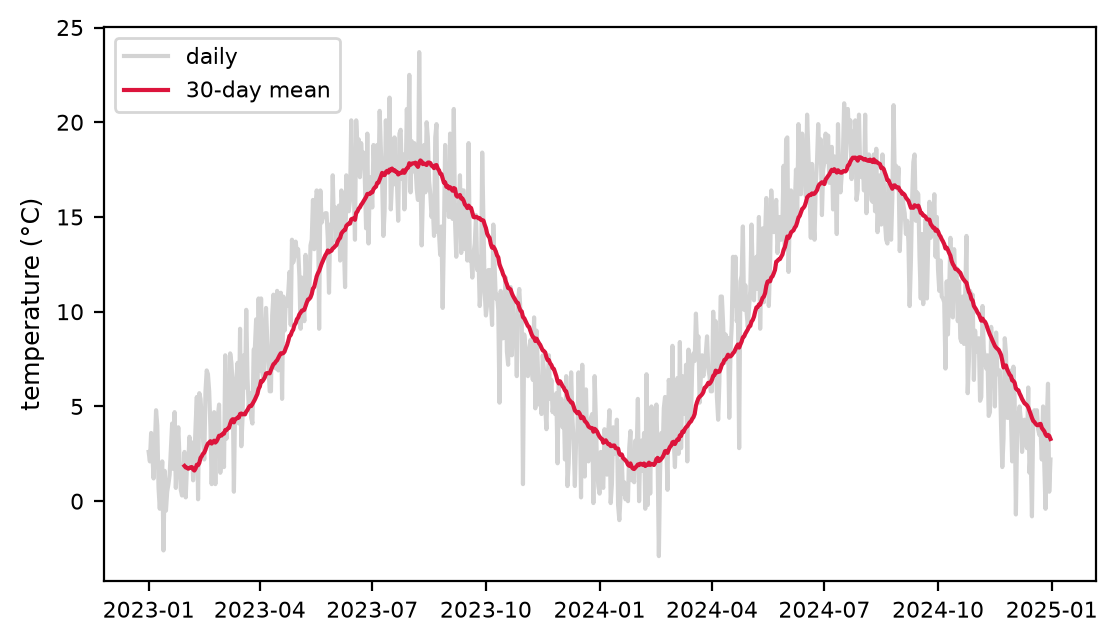

In [731]:
df_ts = df_weather.set_index("date")
plt.plot(df_ts.index, df_ts["temp_c"], color="lightgrey", label="daily")
plt.plot(df_ts.index, df_ts["temp_c"].rolling(30).mean(), color="crimson", label="30-day mean")
plt.ylabel("temperature (°C)")
plt.legend();

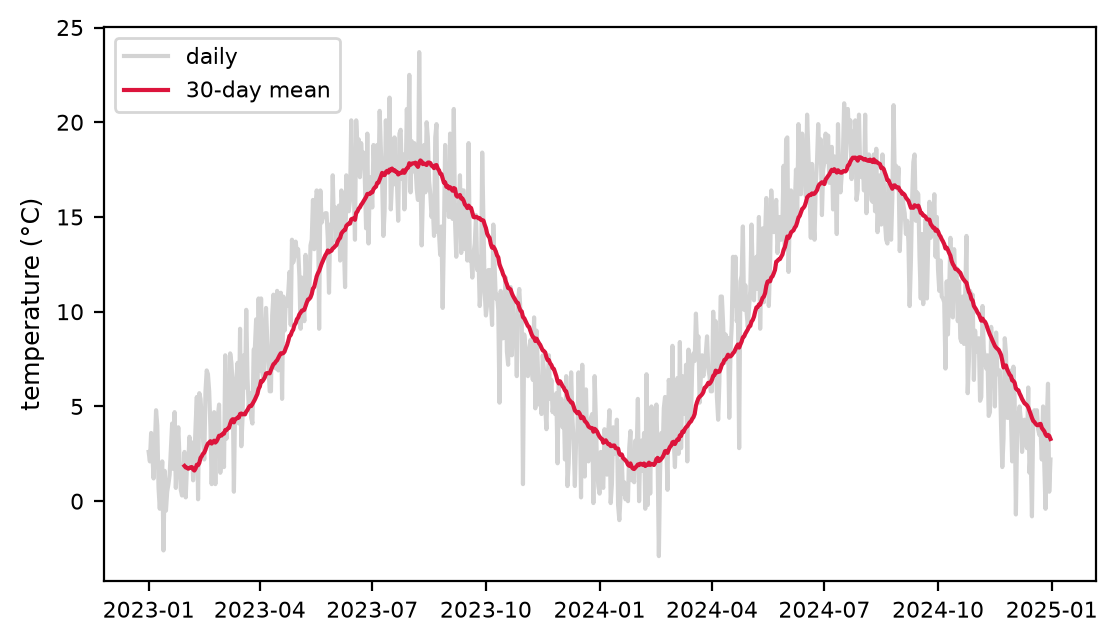

In [732]:
# the same plot in object-oriented style (ax. methods)
df_ts = df_weather.set_index("date")
fig, ax = plt.subplots()
ax.plot(df_ts.index, df_ts["temp_c"], color="lightgrey", label="daily")
ax.plot(df_ts.index, df_ts["temp_c"].rolling(30).mean(), color="crimson", label="30-day mean")
ax.set_ylabel("temperature (°C)")
ax.legend();

*See also:* Resampling to another frequency (B8) · Calculating a rolling average (B8) · Plotting daily and monthly values together (B8) · Plotting a time series with pandas (B8)

#### Plotting a time series with pandas

**B8.34**

`df['col'].plot()`

***(non-examinable)***

The `.plot()` method on a Series with a datetime index allows us to draw a time series without writing any matplotlib. It is useful for quick checks. Alternatively, use matplotlib directly when more control is needed.

With a datetime index, a pandas Series plots itself with dates on the axis.

In [733]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


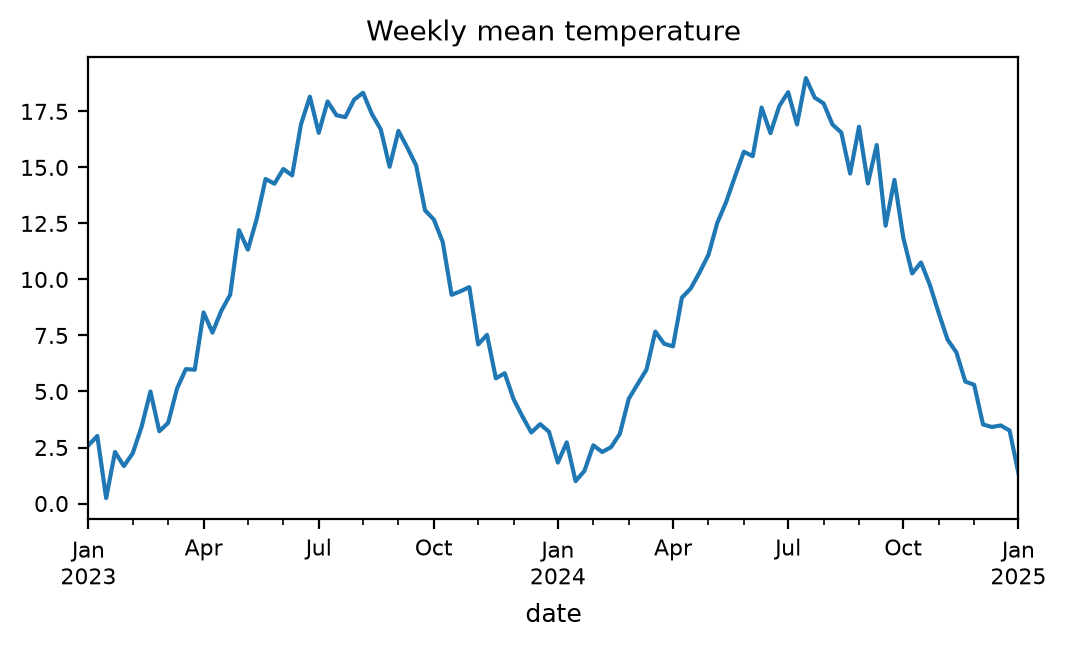

In [734]:
df_ts = df_weather.set_index("date")
df_ts["temp_c"].resample("W").mean().plot(figsize=(6, 3), title="Weekly mean temperature");

*See also:* Plotting a time series (B8) · Plotting a scatter with pandas (B5) · Plotting monthly totals as bars (B8)

#### Plotting monthly totals as bars

**B8.35**

`monthly.plot.bar()`

***(non-examinable)***

The `.plot.bar()` method allows us to show totals per month as bars. It is useful for amounts that accumulate over time. Alternatively, `plt.bar` or `sns.barplot` give the same chart.

In [735]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


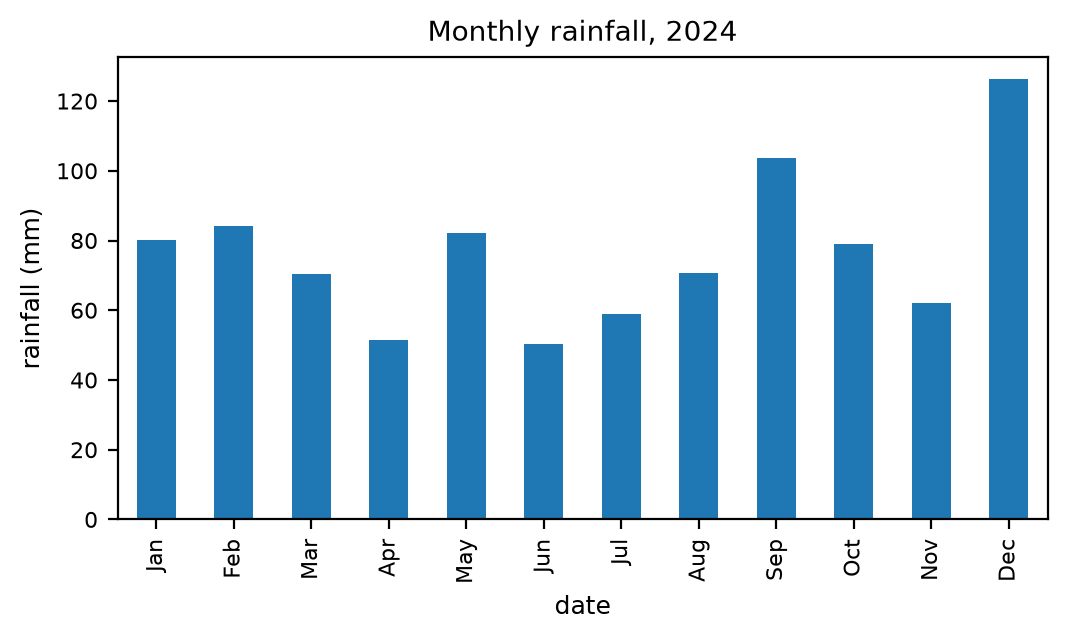

In [736]:
df_ts = df_weather.set_index("date")
col_rain = df_ts.loc["2024", "rain_mm"].resample("ME").sum()
col_rain.index = col_rain.index.strftime("%b")       # label bars with month names
col_rain.plot.bar(figsize=(6, 3), ylabel="rainfall (mm)", title="Monthly rainfall, 2024");

*See also:* Drawing a bar plot of values (C3) · Resampling to another frequency (B8) · Drawing a bar chart (C2)

#### Marking a date on a plot

**B8.36**

`plt.axvline(pd.Timestamp("YYYY-MM-DD"))`

***(non-examinable)***

The `plt.axvline()` function allows us to draw a vertical line at a chosen date. It is useful for marking an event on a time axis. Alternatively, `plt.axvspan` shades a period instead.

In [737]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


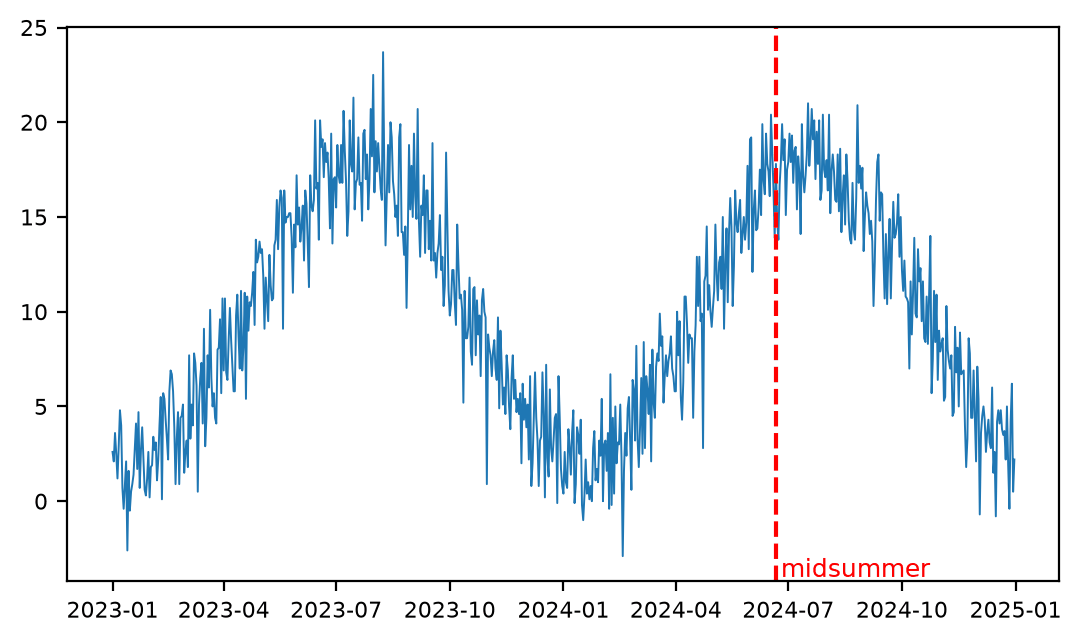

In [738]:
plt.plot(df_weather["date"], df_weather["temp_c"], lw=0.7)
plt.axvline(pd.Timestamp("2024-06-21"), color="red", linestyle="--")
plt.text(pd.Timestamp("2024-06-25"), -4, "midsummer", color="red");

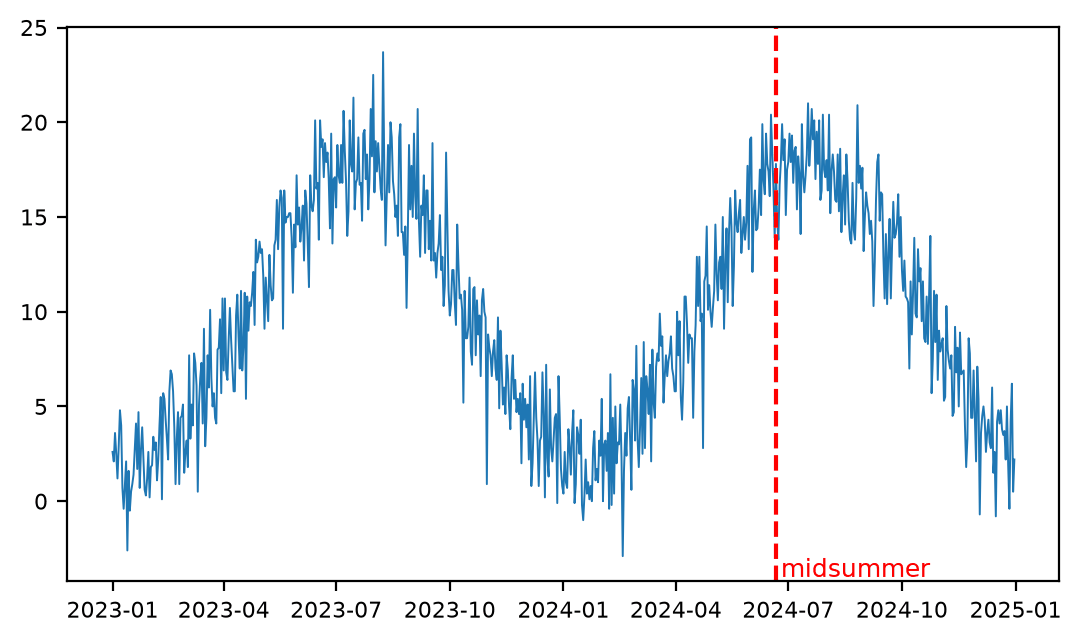

In [739]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(df_weather["date"], df_weather["temp_c"], lw=0.7)
ax.axvline(pd.Timestamp("2024-06-21"), color="red", linestyle="--")
ax.text(pd.Timestamp("2024-06-25"), -4, "midsummer", color="red");

*See also:* Drawing a vertical line (C1) · Shading a period (B8) · Plotting a time series (B8)

#### Shading a period

**B8.37**

`plt.axvspan(start, end, alpha=0.3)`

***(non-examinable)***

The `plt.axvspan()` function allows us to shade a stretch of time on a plot. It is useful for highlighting a season or an intervention period. Alternatively, `plt.axvline` marks a single date.

In [740]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


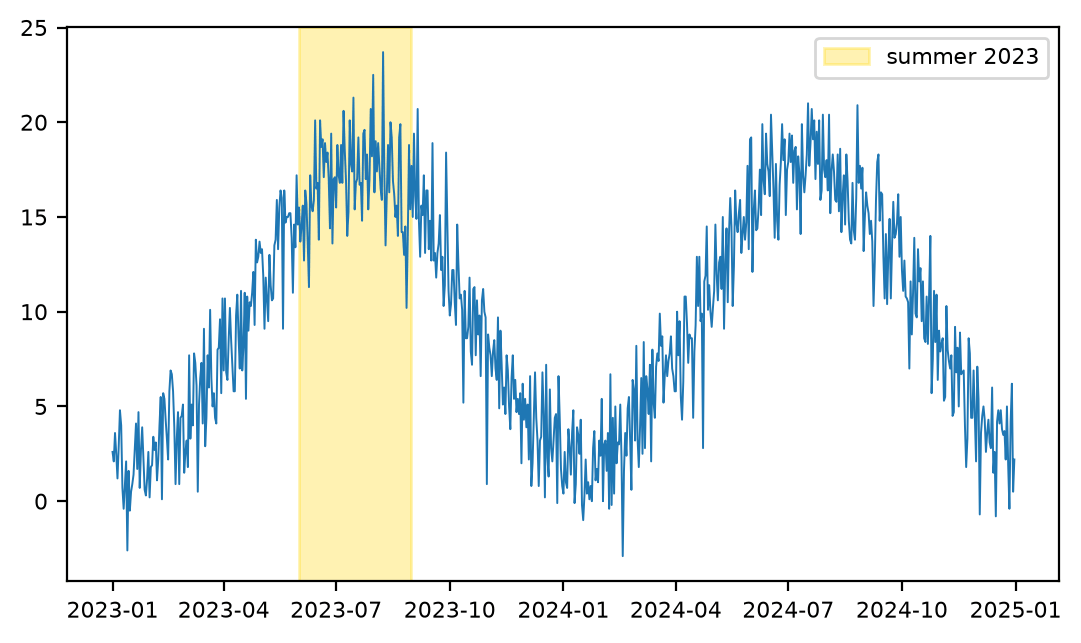

In [741]:
plt.plot(df_weather["date"], df_weather["temp_c"], lw=0.7)
plt.axvspan(pd.Timestamp("2023-06-01"), pd.Timestamp("2023-08-31"), color="gold", alpha=0.3, label="summer 2023")
plt.legend();

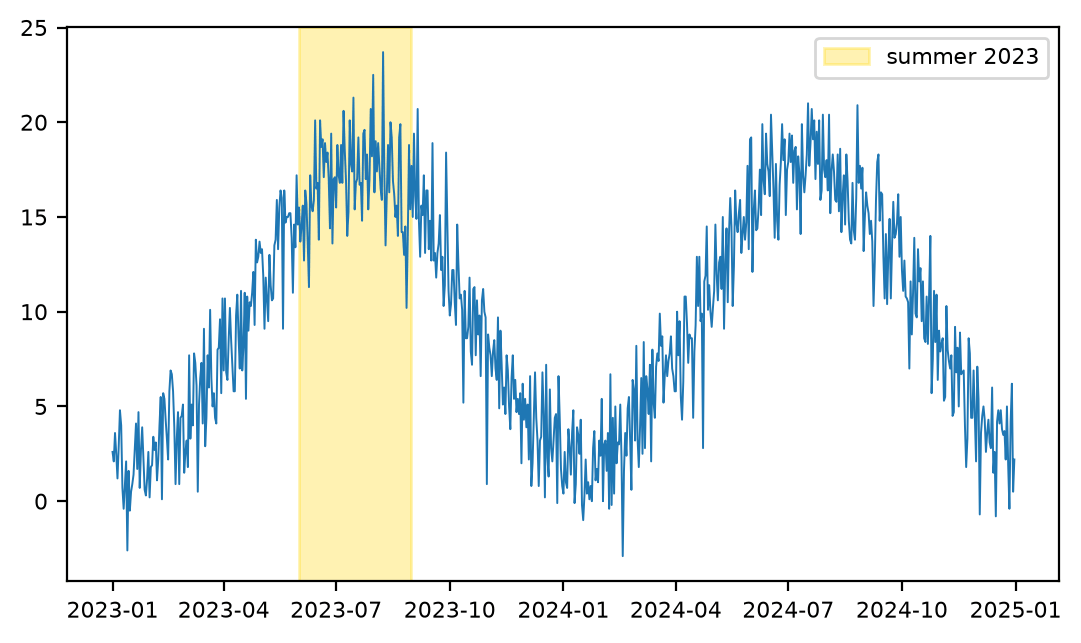

In [742]:
# the same plot in object-oriented style (ax. methods)
fig, ax = plt.subplots()
ax.plot(df_weather["date"], df_weather["temp_c"], lw=0.7)
ax.axvspan(pd.Timestamp("2023-06-01"), pd.Timestamp("2023-08-31"), color="gold", alpha=0.3, label="summer 2023")
ax.legend();

*See also:* Drawing a vertical line (C1) · Marking a date on a plot (B8) · Shading an area (C2) · Plotting months as box plots (B8)

#### Plotting months as box plots

**B8.38**

`sns.boxplot(data=df, x='month', y='temp_c')`

***(non-examinable)***

If we have dates and a measurement, then extracting the month and plotting it as a category compares the spread for each month. It is useful for seasonal patterns. Alternatively, `groupby(...).mean()` shows only the average.

Pull out the month with `.dt`, then use it as a category.

In [743]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


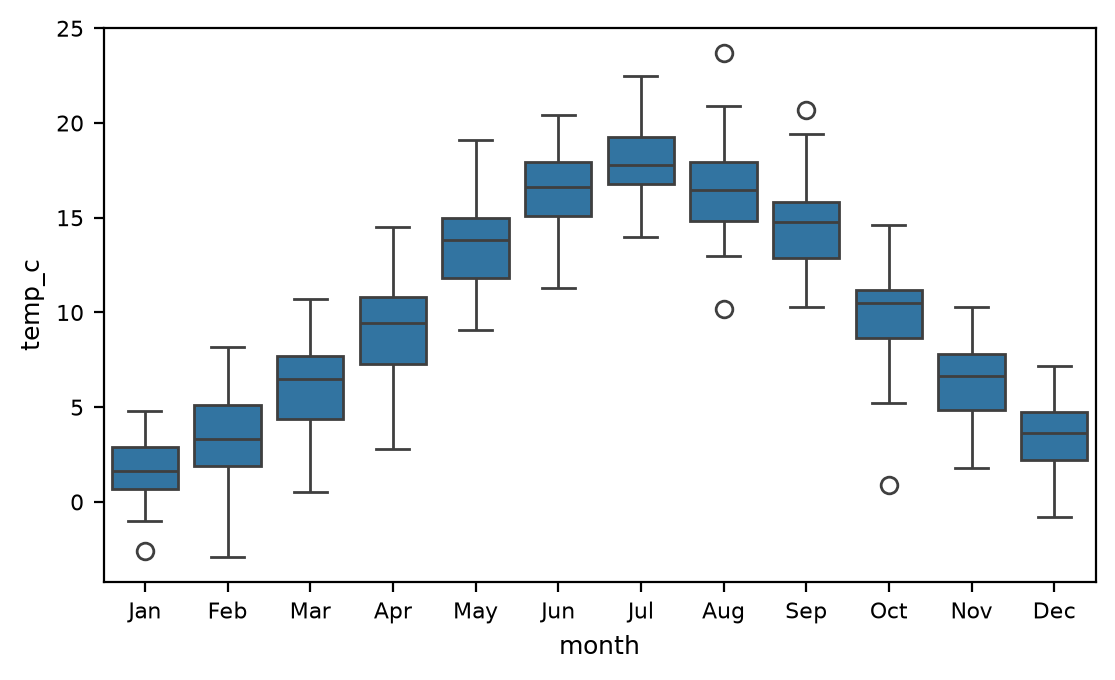

In [744]:
df_w = df_weather.copy()
df_w["month"] = df_w["date"].dt.month_name().str[:3]
order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
sns.boxplot(data=df_w, x="month", y="temp_c", order=order);

*See also:* Grouping and summarising with `groupby` (B9) · Extracting year, month and day (B8) · Drawing a box plot with `boxplot` (C3) · Plotting one line per year (B8)

#### Plotting one line per year

**B8.39**

`sns.lineplot(data=df, x='dayofyear', y='temp_c', hue='year')`

***(non-examinable)***

If we have several years of daily data, then plotting day-of-year with `hue=year` overlays the years on one axis. It is useful for comparing the same season across years. Alternatively, use separate subplots, one per year.

Compare years by plotting day-of-year on the x axis.

In [745]:
# display the example data
df_weather.head()

,date,temp_c,rain_mm
0,2023-01-01,2.6,0.5
1,2023-01-02,2.1,4.2
2,2023-01-03,3.6,0.2
3,2023-01-04,2.5,1.5
4,2023-01-05,1.2,3.9


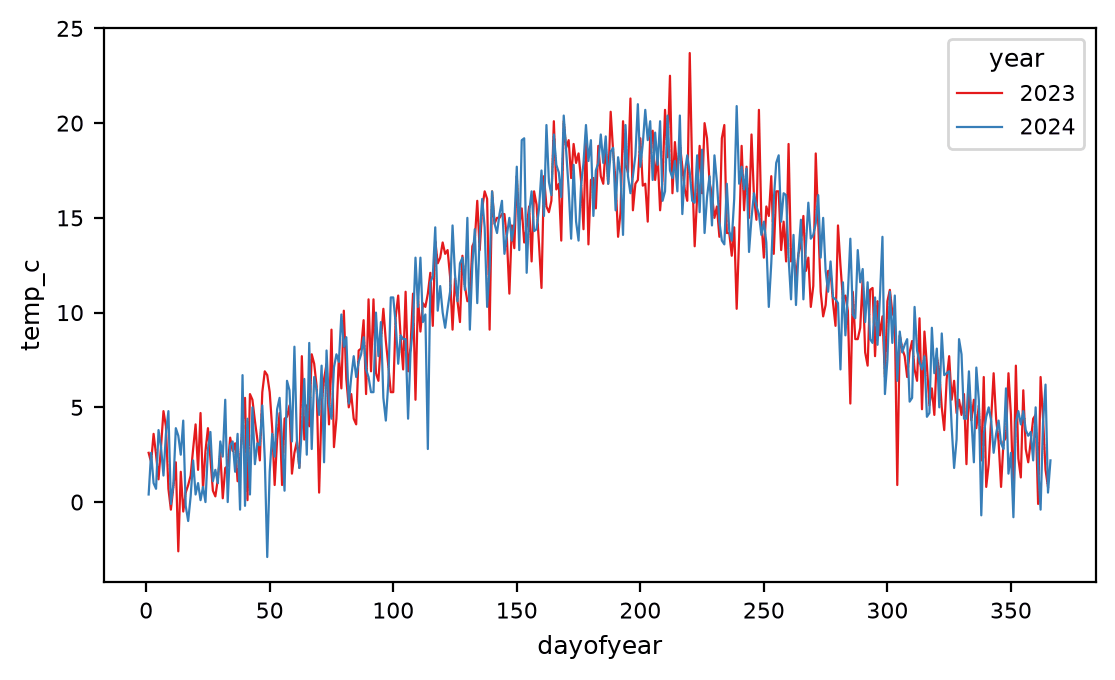

In [746]:
df_w = df_weather.copy()
df_w["year"] = df_w["date"].dt.year
df_w["dayofyear"] = df_w["date"].dt.dayofyear
sns.lineplot(data=df_w, x="dayofyear", y="temp_c", hue="year", palette="Set1", linewidth=0.8);

*See also:* Extracting year, month and day (B8) · Colouring points by group (C3) · Plotting the weekday pattern (B8)

#### Plotting the weekday pattern

**B8.40**

`df.groupby('weekday')['visits'].mean().plot.bar()`

***(non-examinable)***

If we have dated counts, then grouping by weekday name and plotting the mean shows how a quantity varies through the week. It is useful for visits, sales or traffic data. Alternatively, a box plot per weekday shows the spread as well as the mean.

In [747]:
# display the example data
df_visits = pd.DataFrame({"date": pd.date_range("2024-01-01", periods=84, freq="D")})
df_visits

,date
0,2024-01-01
1,2024-01-02
2,2024-01-03
3,2024-01-04
4,2024-01-05
...,...
79,2024-03-20
80,2024-03-21
81,2024-03-22
82,2024-03-23


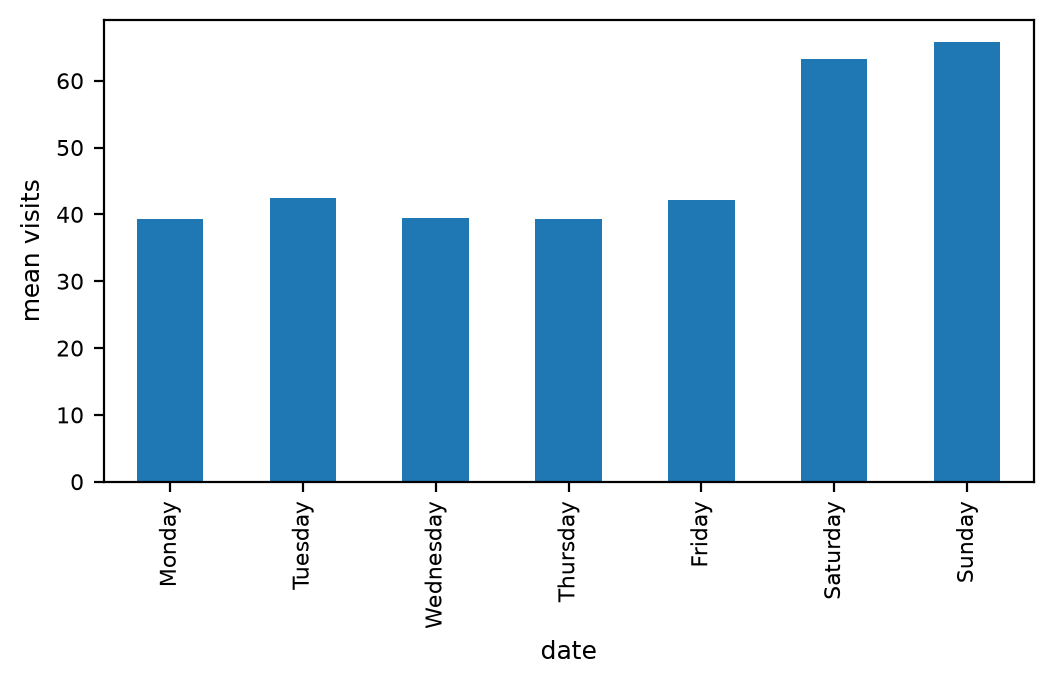

In [748]:
rng = np.random.default_rng(3)
df_visits["n"] = rng.poisson(40, 84) + np.where(df_visits["date"].dt.dayofweek >= 5, 25, 0)   # busier at weekends

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
col_by_day = df_visits.groupby(df_visits["date"].dt.day_name())["n"].mean().reindex(order)
col_by_day.plot.bar(figsize=(6, 3), ylabel="mean visits");

*See also:* Getting weekday and month names (B8) · Grouping by month (B8) · Plotting months as box plots (B8)